In [1]:
import json
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Google Colab
PATH = Path("/content/data")

# Local (comment the line above, then uncomment below)
# PATH = Path("diplomacy-deception-detection/data/raw")

for filename in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    print(filename, ":", (PATH / filename).exists())

train.jsonl : True
validation.jsonl : True
test.jsonl : True


In [3]:
def read_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))
    return records


In [4]:
splits = {}
for split in ["train", "validation", "test"]:
    splits[split] = read_jsonl(PATH / f"{split}.jsonl")
    print(f"{split}: {len(splits[split])} conversations")

train: 189 conversations
validation: 21 conversations
test: 42 conversations


#### message-level DataFrame

In [5]:
rows = []

for split, records in splits.items():
    for conversation_index, record in enumerate(records):
        n = len(record["messages"])
        for field in ["sender_labels", "speakers", "receivers"]:
            if len(record[field]) != n:
                raise ValueError(f"Length mismatch in {split}, conversation {conversation_index}: {field}")

        for i, message in enumerate(record["messages"]):
            rows.append({
                "split": split,
                "game_id": record["game_id"],
                "conversation_index": conversation_index,
                "message_position": i,
                "message": message,
                "speaker": record["speakers"][i],
                "receiver": record["receivers"][i],
                "sender_label": record["sender_labels"][i]
            })

df = pd.DataFrame(rows)
print("All message rows:", len(df))


All message rows: 17289


In [6]:
df.head()

,split,game_id,conversation_index,message_position,message,speaker,receiver,sender_label
0,train,1,0,0,Germany!\n\nJust the person I want to speak wi...,italy,germany,True
1,train,1,0,1,"You've whet my appetite, Italy. What's the sug...",germany,italy,True
2,train,1,0,2,👍,italy,germany,True
3,train,1,0,3,It seems like there are a lot of ways that cou...,germany,italy,True
4,train,1,0,4,"Yeah, I can’t say I’ve tried it and it works, ...",italy,germany,True


#### Select the training messages

To avoid using test-set patterns when designing features, we conduct the linguistic comparisons on training messages only.

In [7]:
train_df = df[df["split"] == "train"].copy()
train_df = train_df[train_df["sender_label"].map(lambda x: type(x) is bool)].copy()
train_df["class"] = train_df["sender_label"].map({
    True: "Truthful",
    False: "Deceptive"
})
train_df["message"] = train_df["message"].fillna("").astype(str)

print("Training messages with valid sender labels:", len(train_df))

Training messages with valid sender labels: 13132


In [8]:
display(train_df["class"].value_counts().to_frame("count"))


,count
class,
Truthful,12541
Deceptive,591


#### Extract simple linguistic features


In [9]:
def count_words(text):
    return len(text.split())

In [10]:
def count_matches(text, pattern):
    return len(re.findall(pattern, text, flags=re.IGNORECASE))


In [11]:
train_df["word_count"] = train_df["message"].apply(count_words)
train_df["character_count"] = train_df["message"].str.len()
train_df["average_word_length"] = train_df["message"].apply(
    lambda text: sum(len(word) for word in text.split()) / len(text.split())
    if text.split() else 0
)
train_df["question_marks"] = train_df["message"].str.count(r"\?")
train_df["exclamation_marks"] = train_df["message"].str.count("!")
train_df["first_person_pronouns"] = train_df["message"].apply(
    lambda text: count_matches(text, r"\b(i|me|my|mine|we|us|our|ours)\b")
)
train_df["second_person_pronouns"] = train_df["message"].apply(
    lambda text: count_matches(text, r"\b(you|your|yours)\b")
)
train_df["negations"] = train_df["message"].apply(
    lambda text: count_matches(text, r"\b(no|not|never|nothing|neither|cannot|can't|won't|don't|didn't|isn't|aren't)\b")
)
train_df["uncertainty_words"] = train_df["message"].apply(
    lambda text: count_matches(text, r"\b(maybe|perhaps|possibly|probably|might|could|unsure|uncertain)\b")
)
train_df["certainty_words"] = train_df["message"].apply(
    lambda text: count_matches(text, r"\b(definitely|certainly|surely|always|never|guarantee|certain)\b")
)

feature_columns = [
    "word_count", "character_count", "average_word_length",
    "question_marks", "exclamation_marks", "first_person_pronouns",
    "second_person_pronouns", "negations", "uncertainty_words",
    "certainty_words"
]

display(train_df[["class", "message"] + feature_columns].head())

,class,message,word_count,character_count,average_word_length,question_marks,exclamation_marks,first_person_pronouns,second_person_pronouns,negations,uncertainty_words,certainty_words
0,Truthful,Germany!\n\nJust the person I want to speak wi...,87,469,4.344828,3,1,9,2,2,2,2
1,Truthful,"You've whet my appetite, Italy. What's the sug...",8,54,5.875000,1,0,1,1,0,0,0
2,Truthful,👍,1,1,1.000000,0,0,0,0,0,0,0
3,Truthful,It seems like there are a lot of ways that cou...,31,186,5.032258,0,0,2,1,3,1,0
4,Truthful,"Yeah, I can’t say I’ve tried it and it works, ...",127,639,4.031496,0,0,11,6,7,0,2


#### Compare message lengths

In [12]:
length_summary = train_df.groupby("class")[["word_count", "character_count"]].agg(
    ["count", "mean", "median", "std"]
).round(2)
length_summary


word_count                      character_count                 \
               count   mean median    std           count    mean median   
class                                                                      
Deceptive        591  29.99   20.0  29.33             591  153.30  102.0   
Truthful       12541  20.36   14.0  21.79           12541  105.35   70.0   

                   
              std  
class              
Deceptive  153.70  
Truthful   114.87

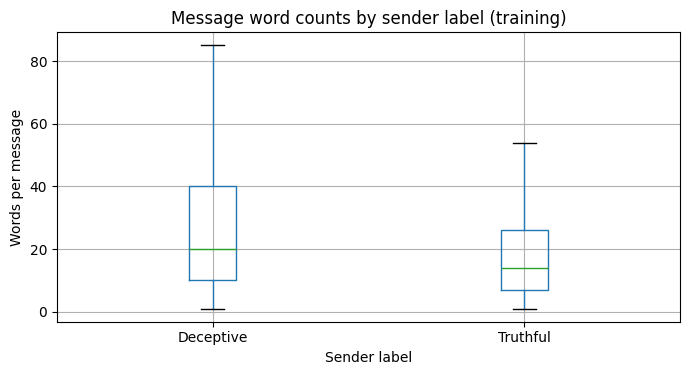

In [13]:

train_df.boxplot(column="word_count", by="class", figsize=(7, 4), showfliers=False)
plt.title("Message word counts by sender label (training)")
plt.suptitle("")
plt.xlabel("Sender label")
plt.ylabel("Words per message")
plt.tight_layout()
plt.show()

#### word-count distribution

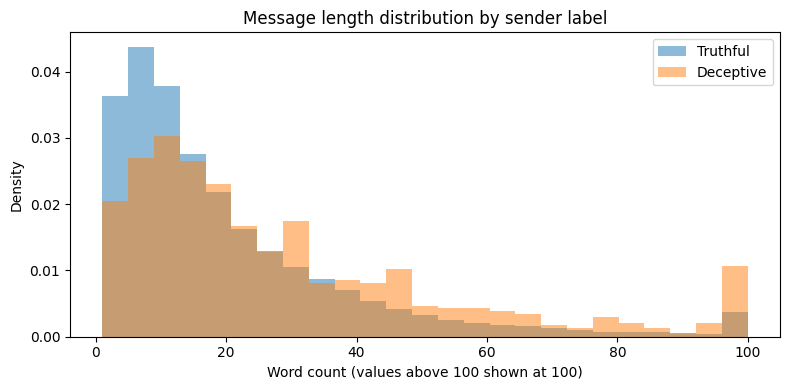

In [14]:
max_words_to_plot = 100

plt.figure(figsize=(8, 4))
for label in ["Truthful", "Deceptive"]:
    values = train_df.loc[train_df["class"] == label, "word_count"]
    plt.hist(values.clip(upper=max_words_to_plot), bins=25,
             alpha=0.5, label=label, density=True)

plt.xlabel(f"Word count (values above {max_words_to_plot} shown at {max_words_to_plot})")
plt.ylabel("Density")
plt.title("Message length distribution by sender label")
plt.legend()
plt.tight_layout()
plt.show()

#### punctuation usage


In [15]:
for feature in ["question_marks", "exclamation_marks"]:
    train_df[feature + "_per_100_words"] = (
        100 * train_df[feature] / train_df["word_count"].clip(lower=1)
    )

punctuation_features = [
    "question_marks_per_100_words",
    "exclamation_marks_per_100_words"
]
display(train_df.groupby("class")[punctuation_features].mean().round(3))



,question_marks_per_100_words,exclamation_marks_per_100_words
class,,
Deceptive,1.160,0.583
Truthful,3.066,1.230


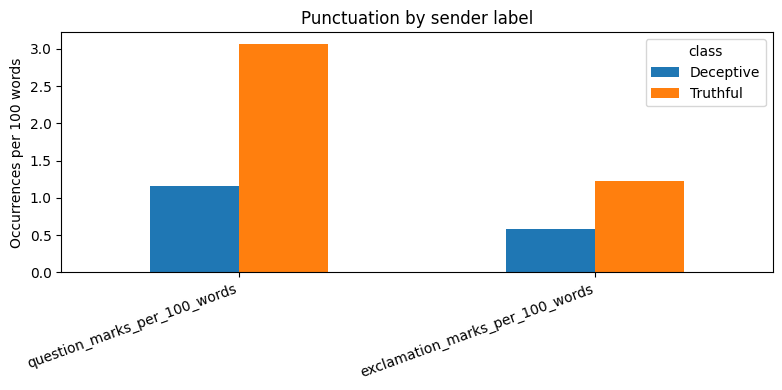

In [16]:
train_df.groupby("class")[punctuation_features].mean().T.plot.bar(figsize=(8, 4))
plt.ylabel("Occurrences per 100 words")
plt.title("Punctuation by sender label")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

#### Compare pronouns

First-person and second-person pronouns may be related to how a speaker presents commitments and addresses another player. Counts are normalized per 100 words.

In [17]:
pronoun_features = ["first_person_pronouns", "second_person_pronouns"]

for feature in pronoun_features:
    train_df[feature + "_per_100_words"] = (
        100 * train_df[feature] / train_df["word_count"].clip(lower=1)
    )

display(train_df.groupby("class")[
    [f + "_per_100_words" for f in pronoun_features]
].mean().round(3))

,first_person_pronouns_per_100_words,second_person_pronouns_per_100_words
class,,
Deceptive,9.176,3.807
Truthful,7.275,4.048


#### Compare negation and uncertainty

The word lists are small, manually defined exploratory dictionaries. They do **not** detect the semantic meaning of a sentence and should not be treated as validated psychological measurements.

In [18]:
lexical_features = ["negations", "uncertainty_words", "certainty_words"]

for feature in lexical_features:
    train_df[feature + "_per_100_words"] = (
        100 * train_df[feature] / train_df["word_count"].clip(lower=1)
    )

lexical_rate_features = [f + "_per_100_words" for f in lexical_features]
lexical_summary = train_df.groupby("class")[lexical_rate_features].mean().round(3)
lexical_summary


,negations_per_100_words,uncertainty_words_per_100_words,certainty_words_per_100_words
class,,,
Deceptive,1.538,0.725,0.186
Truthful,1.603,0.561,0.195


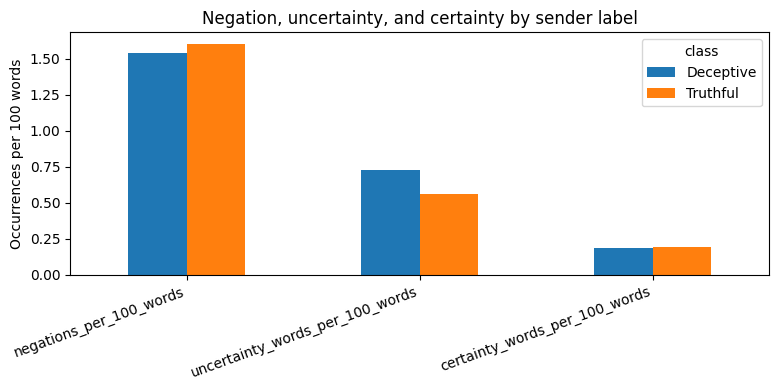

In [19]:

lexical_summary.T.plot.bar(figsize=(8, 4))
plt.ylabel("Occurrences per 100 words")
plt.title("Negation, uncertainty, and certainty by sender label")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

#### Summarize all features

Compare the mean values by sender class. These differences are descriptive, not causal.

In [20]:
rate_features = punctuation_features + [
    f + "_per_100_words" for f in pronoun_features + lexical_features
]

comparison_features = ["word_count", "character_count", "average_word_length"] + rate_features

feature_summary = train_df.groupby("class")[comparison_features].mean().T
feature_summary["Deceptive minus Truthful"] = (
    feature_summary["Deceptive"] - feature_summary["Truthful"]
)
display(feature_summary.round(3))

class,Deceptive,Truthful,Deceptive minus Truthful
word_count,29.995,20.359,9.636
character_count,153.296,105.352,47.945
average_word_length,4.112,4.307,-0.195
question_marks_per_100_words,1.160,3.066,-1.907
exclamation_marks_per_100_words,0.583,1.230,-0.647
first_person_pronouns_per_100_words,9.176,7.275,1.901
second_person_pronouns_per_100_words,3.807,4.048,-0.241
negations_per_100_words,1.538,1.603,-0.065
uncertainty_words_per_100_words,0.725,0.561,0.164
certainty_words_per_100_words,0.186,0.195,-0.009


#### Check whether results vary by game


In [21]:
game_summary = (
    train_df.groupby(["game_id", "class"])["word_count"]
    .mean()
    .unstack()
)
display(game_summary.round(2))



class,Deceptive,Truthful
game_id,,
1,38.66,27.65
2,15.15,11.94
3,17.78,20.69
5,15.29,15.07
6,47.18,33.06
7,16.78,21.14
8,19.48,19.92
9,32.50,19.61
10,39.73,27.74


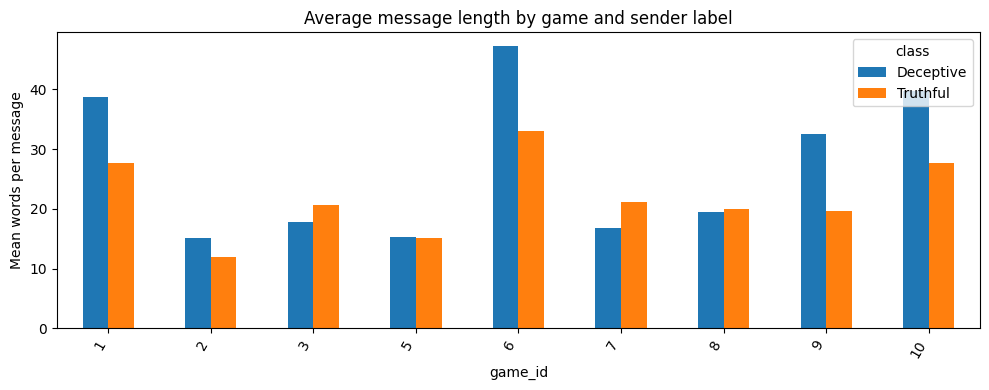

In [22]:
game_summary.plot.bar(figsize=(10, 4))
plt.ylabel("Mean words per message")
plt.title("Average message length by game and sender label")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

#### sample messages

In [23]:
for label in ["Truthful", "Deceptive"]:
    print("\n", label, "examples:")
    sample = train_df[train_df["class"] == label].head(3)
    display(sample[[
        "game_id", "speaker", "receiver", "message",
        "word_count", "negations", "uncertainty_words"
    ]])


 Truthful examples:


,game_id,speaker,receiver,message,word_count,negations,uncertainty_words
0,1,italy,germany,Germany!\n\nJust the person I want to speak wi...,87,2,2
1,1,germany,italy,"You've whet my appetite, Italy. What's the sug...",8,0,0
2,1,italy,germany,👍,1,0,0



 Deceptive examples:


,game_id,speaker,receiver,message,word_count,negations,uncertainty_words
132,1,italy,germany,I really don’t think that’s a fair description...,24,0,0
135,1,italy,germany,"We’re friends, right? I believe that every sin...",33,0,0
139,1,italy,germany,I have to say that I’m surprised that you feel...,46,0,1
